### Collect data

In [1]:
import pandas as pd
datacol = pd.read_csv('./data/benchmark_24-replicas.csv')
datacol.head()

,adapter,directory,path,replica_no,replicas,name,p,n,description,p_informative
0,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,1,24,Continuous Features,20,1600,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...","18,19"
1,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,2,24,Continuous Features,20,1600,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...","18,19"
2,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,3,24,Continuous Features,20,1600,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...","18,19"
3,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,4,24,Continuous Features,20,1600,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...","18,19"
4,rebate,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,./data/rebate/CA_Datasets_Loc_2_Qnt_2_Pop_1000...,5,24,Continuous Features,20,1600,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...","18,19"


In [50]:
from tqdm import tqdm

rankdata = pd.DataFrame()
chunks = []
for _, dataset in tqdm(datacol.iterrows(), total=len(datacol)):
    rankpath = os.path.join('../../results/11714894_subsets/ranking', dataset.path + '.csv')
    rankpath2 = os.path.join('../../results/11824789/ranking', dataset.path + '.csv')

    data = pd.DataFrame()
    if os.path.exists(rankpath):
        data = pd.read_csv(rankpath)
    if os.path.exists(rankpath2):
        data = pd.read_csv(rankpath2)
    if not data.empty:
        dataset = dataset.drop(labels=[\
            'directory', 'path', 'adapter']) # drop some cols to save space
        # add more specific info to the ranking rows; e.g. replica_no, etc.
        rich_data = data.assign(**dataset)
        chunks.append(rich_data)
rankdata = pd.concat(chunks)
del chunks
# rankdata.to_csv('./data/rankdata.csv', index=False)
print('')
rankdata.shape

100%|██████████| 1828/1828 [00:32<00:00, 56.40it/s]



(193755, 12)

Compute additional statistics

In [52]:
print(rankdata.shape)
statdata = rankdata.dropna(subset=['p_informative'])
print(statdata.shape)

(193755, 12)
(168512, 12)


In [65]:
import time
import numpy as np

s = time.time()
statdata['subsets'] = statdata['subset'].str.split(pat=',')
statdata['p_informatives'] = statdata['p_informative'].str.split(pat=',')
statdata['n_p_informatives'] = statdata['p_informatives'].str.len()
statdata['n_positives'] = statdata['subsets'].str.len()
print('{} seconds'.format(time.time() - s))

11.105029106140137 seconds


In [66]:
tqdm.pandas()
def compute_tp_all(x):
    return np.sum(np.isin(x.subsets, x.p_informatives))
statdata['tp'] = statdata.progress_apply(compute_tp_all, axis='columns')

100%|██████████| 168512/168512 [00:33<00:00, 4977.20it/s]


888888889
730 [0.         0.05555556 1.        ] [0.  0.5 1. ] [2 1 0] auc= 0.7222222222222221
731 [0. 0. 1.] [0.  0.5 1. ] [2 1 0] auc= 0.75
732 [0. 0. 1.] [0. 1. 1.] [2 1 0] auc= 1.0
733 [0. 0. 1.] [0.  0.5 1. ] [2 1 0] auc= 0.75
734 [0.         0.11111111 1.        ] [0. 1. 1.] [2 1 0] auc= 0.9444444444444444
735 [0.         0.88888889 1.        ] [0. 1. 1.] [2 1 0] auc= 0.5555555555555556
736 [0. 1.] [0. 1.] [2 1] auc= 0.5
737 [0.         0.11111111 1.        ] [0. 1. 1.] [2 1 0] auc= 0.9444444444444444
738 [0.         0.88888889 1.        ] [0. 1. 1.] [2 1 0] auc= 0.5555555555555556
739 [0.         0.66666667 1.        ] [0. 1. 1.] [2 1 0] auc= 0.6666666666666667
740 [0.         0.22222222 1.        ] [0. 1. 1.] [2 1 0] auc= 0.8888888888888888
741 [0.         0.33333333 1.        ] [0. 1. 1.] [2 1 0] auc= 0.8333333333333334
742 [0.         0.66666667 1.        ] [0. 1. 1.] [2 1 0] auc= 0.6666666666666667
743 [0. 1.] [0. 1.] [2 1] auc= 0.5
744 [0.         0.55555556 1.        ] [0.

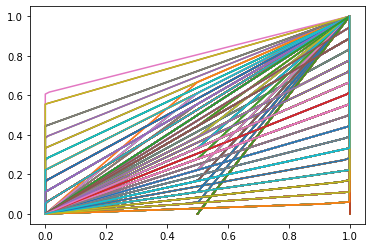

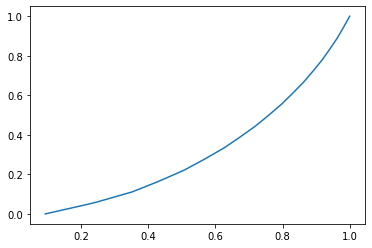

In [137]:
tprs = []
mean_fpr = np.linspace(0, 1, 100)
for i in range(1000):
# i = 0
    p = statdata['p'].astype(int).values[i]
    y_true = np.zeros(p, dtype=np.int8)
    y_pred = np.zeros(p, dtype=np.int8)

    p_ = list(map(lambda x: int(x), statdata['p_informatives'].values[i]))
    y_true[p_] = 1
    s_ = list(map(lambda x: int(x), statdata['subsets'].values[i]))
    y_pred[s_] = 1

    from sklearn.metrics import precision_recall_fscore_support, roc_curve, auc
    fpr, tpr, thresholds = roc_curve(y_true, y_pred)
    aucscore = auc(fpr, tpr)
    interpolated_tpr = np.interp(mean_fpr, fpr, tpr)
    plt.plot(interpolated_tpr, mean_fpr)
    tprs.append(interpolated_tpr)
    # print('y_true', y_true, 'y_pred', y_pred)
    # if len(fpr) > 3:
    print(i, fpr, tpr, thresholds, 'auc=', aucscore)
    #     break
plt.show()
plt.plot(np.mean(tprs, axis=0), mean_fpr)

In [ ]:
# tpr/fpr ROC computation based on sklearn.metrics.roc_curve and https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc_crossval.html
# threshold_idxs = [n_positives - 1, p - 1]
# tps = [n_p_informatives, n_p_informatives]
# fps = 1 + threshold_idxs - tps
# tpr = np.r_[0, tps] / tps[-1]
# fpr = np.r_[0, fps] / fps[-1]

In [71]:
s = time.time()
statdata['fp']          = statdata['n_positives'] - statdata['tp']
statdata['fn']          = statdata['n_p_informatives'] - statdata['tp']
statdata['tn']          = statdata['p'].astype(int) - statdata['n_positives']
statdata['recall']      = statdata['tp'] / statdata['n_p_informatives']
statdata['precision']   = statdata['tp'] / statdata['n_positives']
statdata['fpr']         = statdata['fp'] / (statdata['fp'] + statdata['tn'])
statdata['f1']          = 2 * ((statdata['precision'] * statdata['recall']) / \
                               (statdata['precision'] + statdata['recall']))
print('{} seconds'.format(time.time() - s))

statdata successfully exported.
2.555187940597534 seconds


In [145]:
fprs = np.linspace(0, 1, 100)
def compute_interpolated_fpr(x):
    return fprs[np.abs(fprs - x.fpr).argmin()]
statdata['roc_fpr'] = statdata.progress_apply(compute_interpolated_fpr, axis='columns')

100%|██████████| 168512/168512 [00:10<00:00, 15374.94it/s]


In [146]:
def compute_interpolated_tpr(x):
    return np.interp(x.roc_fpr, [0, x.fpr ,1],[0, x.recall, 1])
statdata['roc_tpr'] = statdata.progress_apply(compute_interpolated_tpr, axis='columns')

100%|██████████| 168512/168512 [00:28<00:00, 5943.96it/s]


In [124]:
def compute_aucs(x):
    return np.trapz([0, x.recall, 1], [0, x.fpr, 1])
statdata['auc'] = statdata.progress_apply(compute_aucs, axis='columns')

100%|██████████| 168512/168512 [00:24<00:00, 6896.37it/s]


In [147]:
statdata.to_csv('./data/statdata.csv',\
    columns=[
        'description', 'ranking_method', 'replica_no',  # identifiers
        'name',                                         # semantics
        'cpu_time', 'feature_rank',                     # raw experiment data
        'recall', 'precision', 'fpr', 'f1',             # metrics
        'roc_fpr', 'roc_tpr'                            # metrics
    ], 
    index=False)
print('statdata successfully exported.')

statdata successfully exported.


everything right (array([1., 1.]), array([1., 1.]), array([1., 1.]), array([4, 2]))
one too much positive (array([0.75, 1.  ]), array([1.        , 0.66666667]), array([0.85714286, 0.8       ]), array([3, 3]))
1 wrong (array([0.75, 0.5 ]), array([0.75, 0.5 ]), array([0.75, 0.5 ]), array([4, 2]))


(array([0.  , 0.25, 1.  ]), array([0. , 0.5, 1. ]), array([2, 1, 0]))

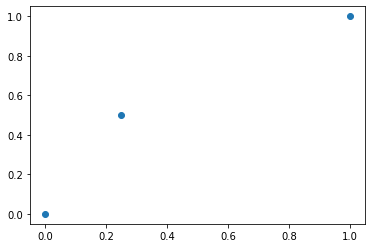

In [79]:
from sklearn.metrics import precision_recall_fscore_support, roc_curve
# 6-bit multiplexer
p_informative = [4, 5]
feature_indexes = [0, 1, 2, 3, 4, 5] # p=6
y_true = [False, False, False, False, True, True]
print('everything right', precision_recall_fscore_support([False, False, False, False, True, True], y_true))
print('one too much positive', precision_recall_fscore_support([False, False, False, True, True, True], y_true))
print('1 wrong', precision_recall_fscore_support([False, False, False, True, True, False], y_true))
y_pred = [False, False, False, True, True, False]
fpr, tpr, thresholds = roc_curve(y_true, y_pred)
import matplotlib.pyplot as plt
plt.scatter(fpr, tpr, label='example')
roc_curve(y_true, y_pred)

In [144]:
statdata

,cpu_time,feature_index,feature_rank,ranking_method,subset,replica_no,replicas,name,p,n,...,fn,tn,recall,precision,fpr,f1,n_p_informatives,auc,tpr,fpr_interp
0,3.855204,0,4.0,RFE w/XGBoost,"0,3,7,8,18,19",1,24,Continuous Features,20,1600,...,0,14,1.0,0.333333,0.222222,0.500000,2,0.888889,1.000000,0.222222
1,3.855204,1,11.0,RFE w/XGBoost,"0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19",1,24,Continuous Features,20,1600,...,0,0,1.0,0.100000,1.000000,0.181818,2,0.500000,1.000000,1.000000
2,3.855204,2,5.0,RFE w/XGBoost,"0,2,3,7,8,10,18,19",1,24,Continuous Features,20,1600,...,0,12,1.0,0.250000,0.333333,0.400000,2,0.833333,1.000000,0.333333
3,3.855204,3,3.0,RFE w/XGBoost,"3,7,18,19",1,24,Continuous Features,20,1600,...,0,16,1.0,0.500000,0.111111,0.666667,2,0.944444,1.000000,0.111111
4,3.855204,4,11.0,RFE w/XGBoost,"0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19",1,24,Continuous Features,20,1600,...,0,0,1.0,0.100000,1.000000,0.181818,2,0.500000,1.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38,24.113497,18,2.0,MultiSURF,"18,19",24,24,2 Additive Main Effects,20,1600,...,0,18,1.0,1.000000,0.000000,1.000000,2,1.000000,1.000000,0.000000
39,24.113497,19,1.0,MultiSURF,19,24,24,2 Additive Main Effects,20,1600,...,1,19,0.5,1.000000,0.000000,0.666667,2,0.750000,0.500000,0.000000
40,24.860639,7,1.0,FeatBoost,7,24,24,2 Additive Main Effects,20,1600,...,2,19,0.0,0.000000,0.050000,NaN,2,0.475000,0.000532,0.050505
41,24.860639,18,2.0,FeatBoost,"7,18",24,24,2 Additive Main Effects,20,1600,...,1,18,0.5,0.500000,0.052632,0.500000,2,0.723684,0.479798,0.050505
